In [1]:
import pacmap 
import numpy        as np
import pandas       as pd
import umap.umap_   as umap

from tqdm                               import tqdm
from sklearn.preprocessing              import StandardScaler, MinMaxScaler
from sklearn.cluster                    import DBSCAN

from utils.Preprocessing                import PreProcessData
from utils.plotFigures                  import linePlot, lineAndScatterPlot, scatterPlot3D, scatterPlot2D
from clustering.plotClustering          import ClusteringResults

# Preprocessing

In [2]:
preData = PreProcessData()
df1Raw  = preData.dataLoading(typeFile='h5')
preData.additionEfficiencyVar()
df      = preData.splitTimeSeries()
dfHealthy = preData.getHealthyState()

scaler          = MinMaxScaler() 
scaledHealthy   = preData.normalizeData(data   = dfHealthy, 
                                        scaler = scaler)
scaledData      = preData.normalizeData(data   = df,
                                        scaler = scaler)

c:\Users\CAEX\Desktop\Diego\Crusher Project\2ndrealdatajournalchile\utils\Preprocessing.py:269: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  self.healthyData    = pd.concat([self.healthyData, healthyPeriod],     ignore_index=True)
c:\Users\CAEX\Desktop\Diego\Crusher Project\2ndrealdatajournalchile\utils\Preprocessing.py:269: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  self.healthyData    = pd.concat([self.healthyData, healthyPeriod],     ignore_index=True)
c:\Users\CAEX\Desktop\Diego\Crusher 

In [3]:
df=preData.crusher1

In [4]:
scaledHealthy['period']     = scaledHealthy['tiempo'].dt.strftime('%d-%m-%Y %H')
df['period']   = df['tiempo'].dt.strftime('%d-%m-%Y %H')

# Healthy Data Clustering

In [5]:
dfEfficiencyVar = scaledHealthy[preData.efficiencyCr1 + preData.newEfficiencyCr1]

clusteringModels    = {'umap':   DBSCAN(min_samples = 150,
                                        eps         = 2.2),

                       'pacmap': DBSCAN(min_samples = 200,
                                        eps         = 3  )} 

dimReductionModels  = {'umap':   umap.UMAP(n_components = 2, 
                                           random_state = 40),

                       'pacmap': pacmap.PaCMAP(n_components = 2, 
                                               random_state = 40, 
                                               save_tree    = True)}

c:\Users\CAEX\Desktop\Diego\Crusher Project\2ndrealdatajournalchile\mmodal\Lib\site-packages\pacmap\pacmap.py:828: UserWarning: Warning: random state is set to 40
  warnings.warn(f'Warning: random state is set to {_RANDOM_STATE}')


In [6]:
Clusters = ClusteringResults(data                = scaledHealthy, 
                             dataNormalized      = dfEfficiencyVar, 
                             clusteringModels    = clusteringModels, 
                             dimReductionModels  = dimReductionModels)

In [7]:
# Get embedding space using Helathy Data
Clusters.train()

c:\Users\CAEX\Desktop\Diego\Crusher Project\2ndrealdatajournalchile\mmodal\Lib\site-packages\umap\umap_.py:1945: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(f"n_jobs value {self.n_jobs} overridden to 1 by setting random_state. Use no seed for parallelism.")


In [8]:
# Get clusters for each trajectory
for trajectory in tqdm(Clusters.trajectories):
    Clusters.getResults(trajectory)

100%|██████████| 24/24 [01:34<00:00,  3.94s/it]


## Embedding Space

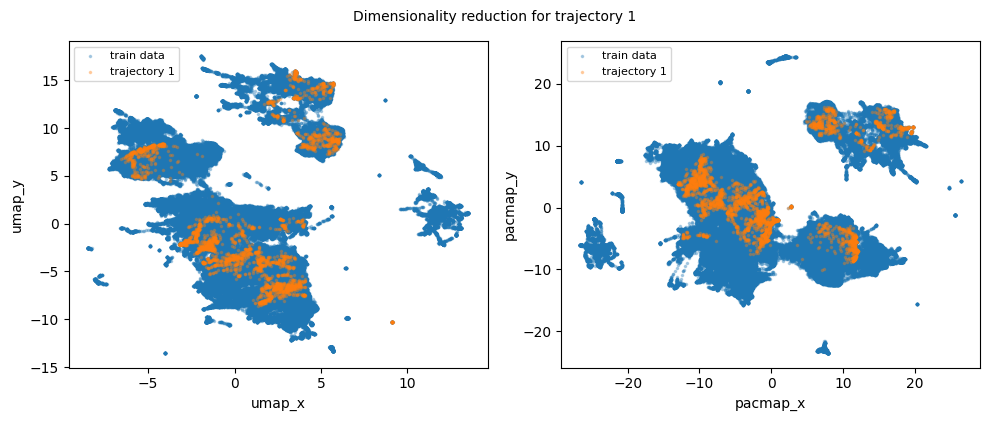

In [9]:
Clusters.plotEmbedding(nfigures=1)

## Clusters Results

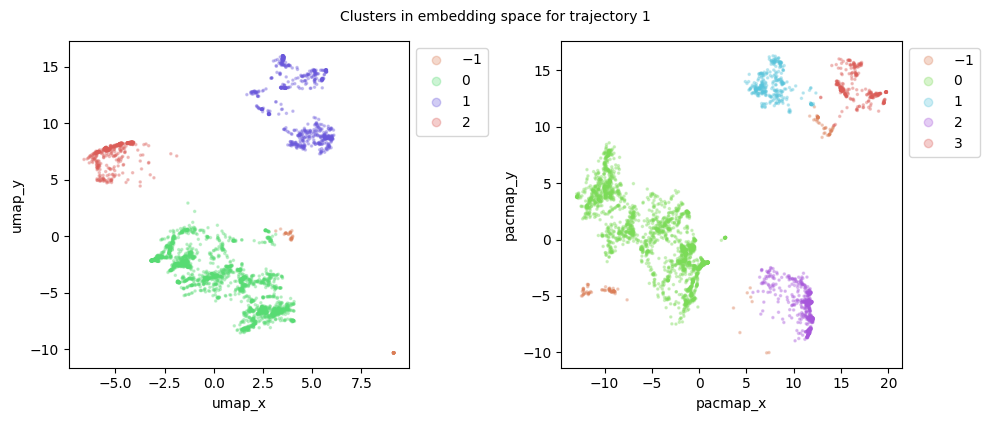

In [10]:
Clusters.plotResults(nfigures=1)

In [39]:
# Clusters.plotFigure('lineplot', 
#                     idxTrajectory   = 3, 
#                     idxVariable     = 8, 
#                     algorithm       = 'pacmap')

# Results by trajectory

In [12]:
dfEfficiencyVar     = scaledData[preData.efficiencyCr1 + preData.newEfficiencyCr1]

clusteringModels    = {'umap':   DBSCAN(min_samples = 150,
                                        eps         = 2.2),

                       'pacmap': DBSCAN(min_samples = 200,
                                        eps         = 3  )} 

dimReductionModels  = Clusters.dimReductionModels # Trained models

In [13]:
ClustersData = ClusteringResults(data                = scaledData, 
                                      dataNormalized      = dfEfficiencyVar, 
                                      clusteringModels    = clusteringModels, 
                                      dimReductionModels  = dimReductionModels)

In [14]:
ClustersData.embeddingTrain = Clusters.embeddingTrain # trained embedding space with healthy data

In [15]:
scaledData['period'] = scaledData['tiempo'].dt.strftime('%d-%m-%Y %H')

In [16]:
# Get clusters for each trajectory
for trajectory in tqdm(ClustersData.trajectories):
    ClustersData.getResults(trajectory)

100%|██████████| 24/24 [02:21<00:00,  5.89s/it]


In [24]:
import plotly.express as px
def scatterPlot2D(data, x, y, color, title='Scatterplot 2D'):
    n_colors = 25 #289
    fig = px.scatter(data, 
                    x      = x, 
                    y      = y, 
                    color  = color,
                    title  = title, 
                    width  = 600, 
                    height = 500,
                    color_discrete_sequence = px.colors.sample_colorscale("Plasma_r", 
                                                                            [n/(n_colors-1) for n in range(n_colors)]))
    fig.show()


def scatterPlot2D(data, x, y, color, title='Scatterplot 2D'):
    n_colors = 24 # 450
    fig = px.scatter(data, 
                    x      = x, 
                    y      = y, 
                    color  = color,
                    title  = title, 
                    width  = 600, 
                    height = 500,
                    color_discrete_sequence = px.colors.sample_colorscale("Plasma_r", 
                                                                          [n/(n_colors-1) for n in range(n_colors)]))
    fig.show()

In [26]:
i=5
d=ClustersData.getTrajectory(i)
d[d['tiempo'].between('2023-03-22 00:44:00', '2023-03-23 00:44:00')];
scatterPlot2D(data=d[d['tiempo'].between('2023-03-22 00:44:00', '2023-03-23 00:44:00')], 
              x='umap_x', 
              y='umap_y', 
              color='period', 
              title=f'Embedding for trajectory {ClustersData.trajectory}')

In [21]:
idx=5
scatterPlot2D(data=ClustersData.getTrajectory(idx), 
              x='pacmap_x', 
              y='pacmap_y', 
              color='period', 
              title=f'Embedding for trajectory {ClustersData.trajectory}')